In [ ]:
import os, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from google.colab import files
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

uploaded = files.upload()          # a file picker appears: choose diabetic_data.csv

BASE = "/content"
DATA = "/content/diabetic_data.csv"
FIG  = f"{BASE}/figures"
os.makedirs(FIG, exist_ok=True)
RS = 42

def save(name):
    plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")

import sklearn; print("scikit-learn", sklearn.__version__)

Saving diabetic_data.csv to diabetic_data (1).csv
Saving IDS_mapping.csv to IDS_mapping.csv
scikit-learn 1.6.1


In [ ]:
df = pd.read_csv(DATA, na_values=["?"])     # the file writes missing values as "?"
print(df.shape)
df.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64
Exact duplicate rows: 0
Repeated patient ids: 30248


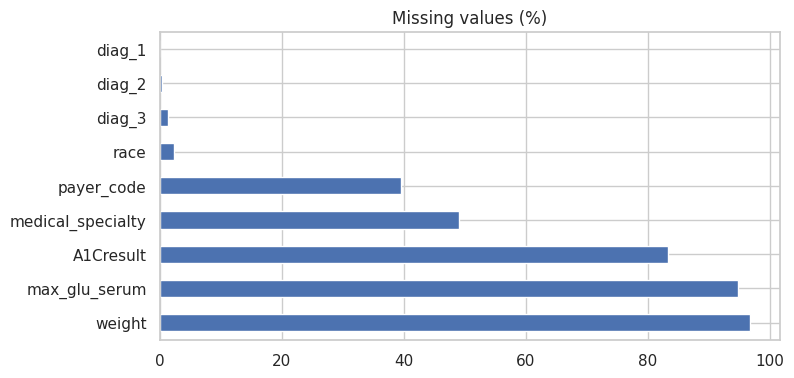

In [ ]:
df.info()
display(df.describe().T)
miss = (df.isna().mean()*100).sort_values(ascending=False)
print(miss[miss > 0].round(2))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated patient ids:", df["patient_nbr"].duplicated().sum())

miss[miss > 0].plot(kind="barh", figsize=(8,4), title="Missing values (%)")
save("eda_missing"); plt.show()

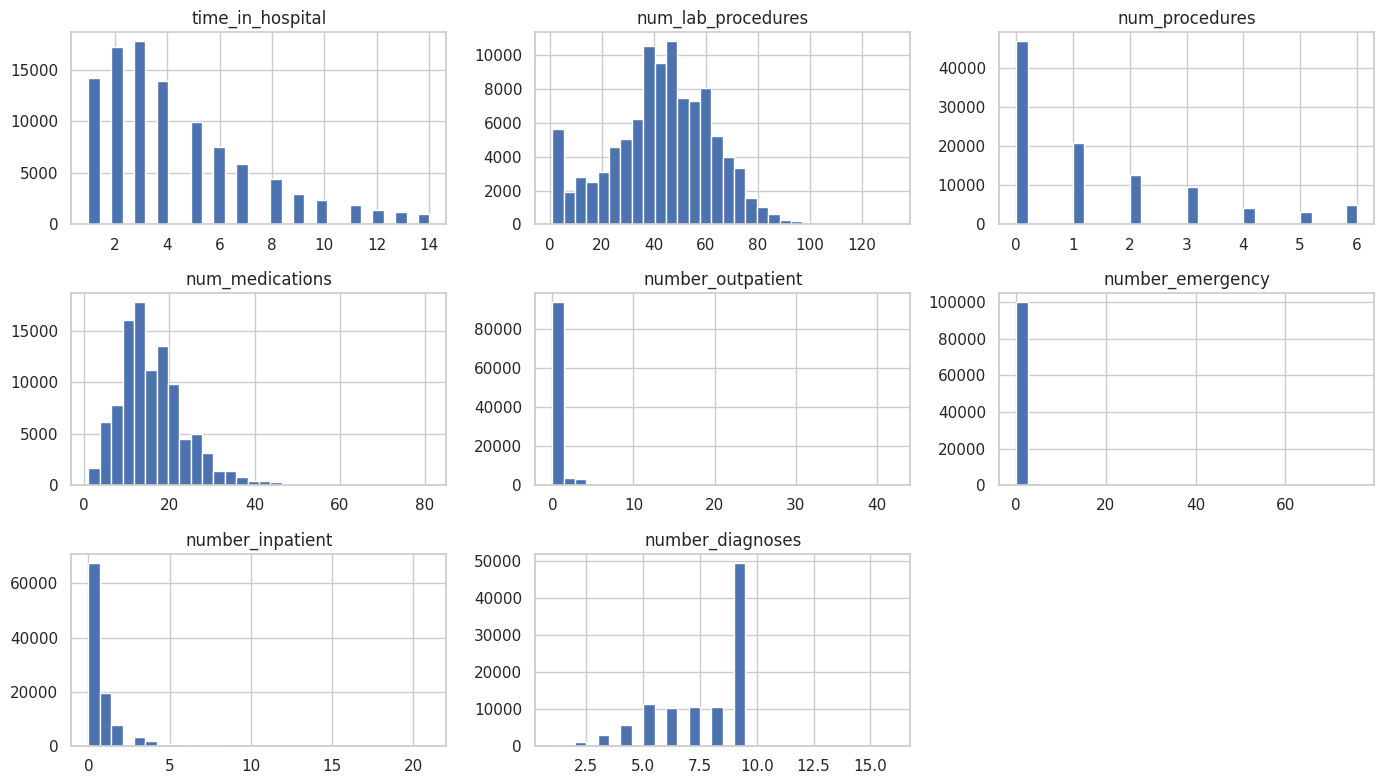

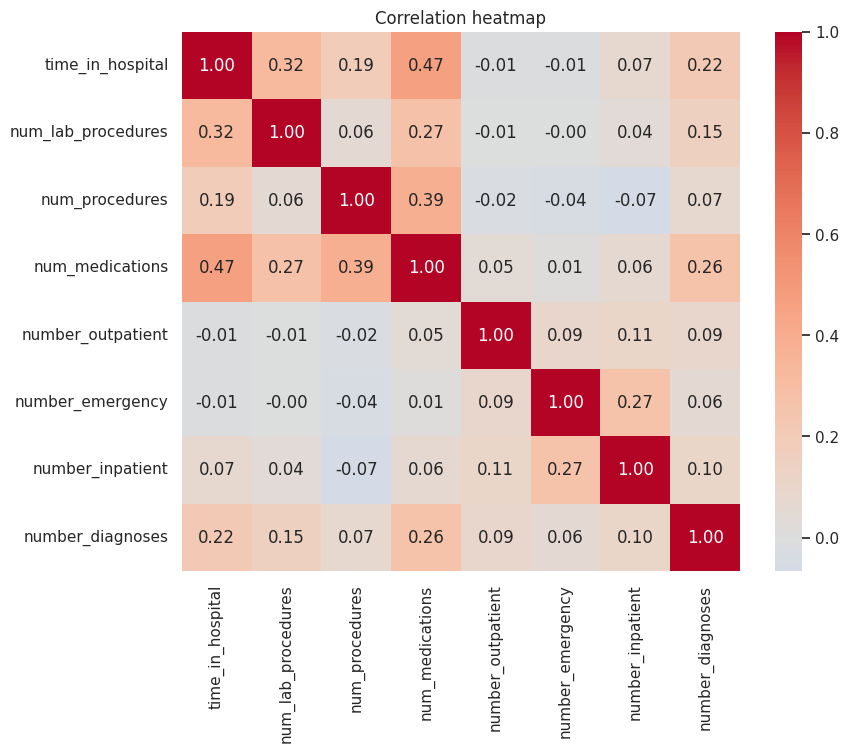

In [ ]:
num_eda = ["time_in_hospital","num_lab_procedures","num_procedures","num_medications",
           "number_outpatient","number_emergency","number_inpatient","number_diagnoses"]
df[num_eda].hist(bins=30, figsize=(14,8)); plt.tight_layout()
save("eda_numeric_hist"); plt.show()

plt.figure(figsize=(9,7))
sns.heatmap(df[num_eda].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); save("eda_correlation"); plt.show()

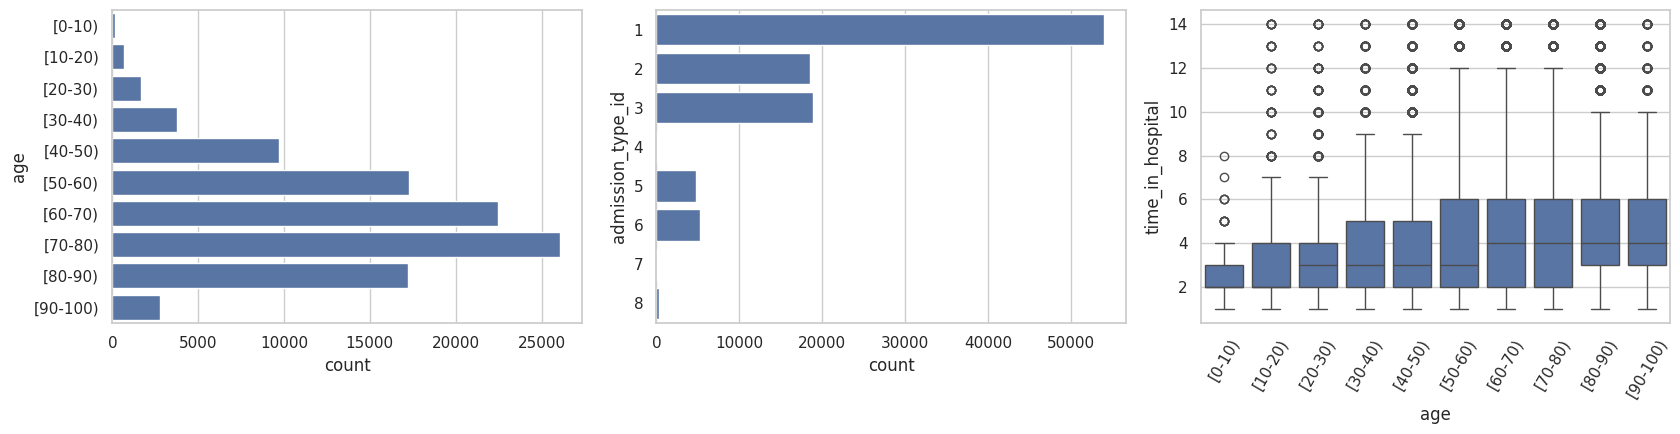

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17,4.5))
sns.countplot(y=df["age"], ax=ax[0])
sns.countplot(y=df["admission_type_id"], ax=ax[1])
sns.boxplot(data=df, x="age", y="time_in_hospital", ax=ax[2]); ax[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); save("eda_categorical_relationships"); plt.show()

In [ ]:
n0 = len(df)
df = df.drop_duplicates()
df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")      # one encounter per patient
df = df[~df["discharge_disposition_id"].isin([11,13,14,19,20,21])].reset_index(drop=True)  # died / hospice
print("Rows before:", n0, "| after cleaning:", len(df))

df["age_mid"] = df["age"].map(lambda a: int(a.strip("[)").split("-")[0]) + 5)

def adm_type(i):  return {1:"Emergency", 7:"Emergency", 2:"Urgent", 3:"Elective"}.get(i, "Other/Unknown")
def adm_source(i):
    if i in (1,2,3): return "Referral"
    if i == 7: return "Emergency Room"
    if i in (4,5,6,10,18,22,25,26): return "Transfer"
    return "Other/Unknown"
def discharge(i):
    if i == 1: return "Home"
    if i in (6,8): return "Home with services"
    if i in (2,3,4,5,9,15,22,23,24,27,28,29,30): return "Facility/Transfer"
    return "Other/Unknown"

df["admission_type_group"]   = df["admission_type_id"].map(adm_type)
df["admission_source_group"] = df["admission_source_id"].map(adm_source)
df["discharge_group"]        = df["discharge_disposition_id"].map(discharge)

spec = df["medical_specialty"].fillna("Unknown")
top8 = spec[spec != "Unknown"].value_counts().head(8).index
df["specialty_group"] = np.where(spec=="Unknown", "Unknown", np.where(spec.isin(top8), spec, "Other"))

Rows before: 101766 | after cleaning: 69973


In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_cols = ["age_mid","time_in_hospital","num_lab_procedures","num_procedures","num_medications",
            "number_outpatient","number_emergency","number_inpatient","number_diagnoses"]
cat_cols = ["admission_type_group","admission_source_group","discharge_group",
            "specialty_group","change","diabetesMed"]

caps = df[num_cols].quantile(0.99).to_dict()      # outliers capped at the 99th percentile
data = df.copy()
for c in num_cols:
    data[c] = data[c].clip(upper=caps[c])

pre = ColumnTransformer([("num", StandardScaler(), num_cols),
                         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])
X = pre.fit_transform(data[num_cols + cat_cols])
print("Model matrix:", X.shape)

Model matrix: (69973, 35)


    k     inertia  silhouette
0   2  771008.083       0.123
1   3  712536.925       0.127
2   4  665843.070       0.097
3   5  626716.365       0.102
4   6  586679.457       0.108
5   7  558155.253       0.107
6   8  538680.029       0.104
7   9  523243.032       0.096
8  10  509699.872       0.093


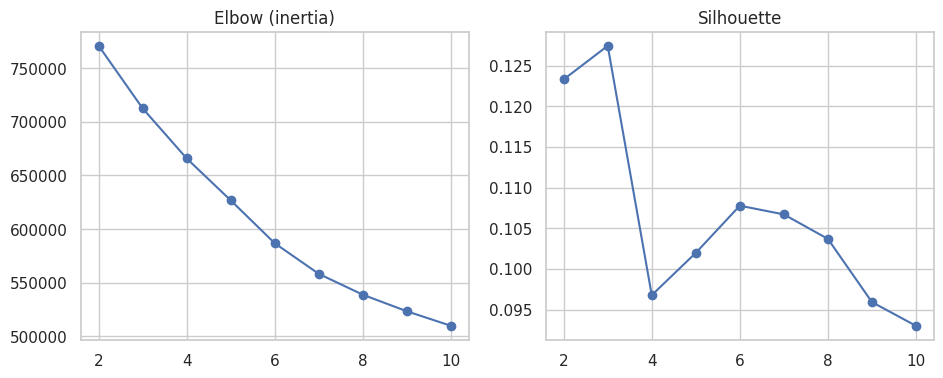

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

rows = []
for k in range(2, 11):
    m = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
    rows.append((k, m.inertia_, silhouette_score(X, m.labels_, sample_size=10000, random_state=RS)))
search = pd.DataFrame(rows, columns=["k","inertia","silhouette"]); print(search.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(search.k, search.inertia, "o-"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(search.k, search.silhouette, "o-"); ax[1].set_title("Silhouette")
save("kmeans_elbow_silhouette"); plt.show()

In [ ]:
k = 4     # <-- replace with YOUR chosen value (I use the best silhouette among k >= 3)
km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
df["kmeans"] = km.labels_
print(df["kmeans"].value_counts().sort_index())

kmeans
0     4878
1    28263
2    14558
3    22274
Name: count, dtype: int64


Components for 90% variance: 14 | PC1+PC2 explain: 28.3 %


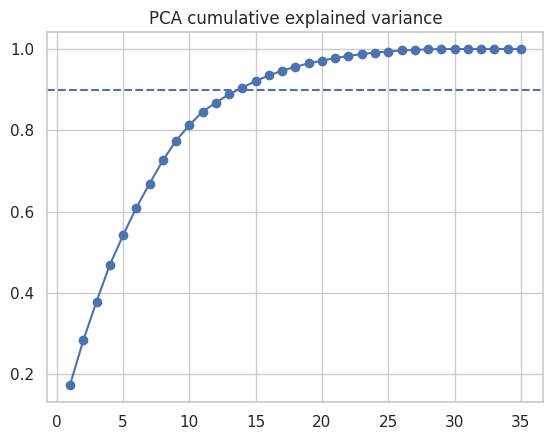

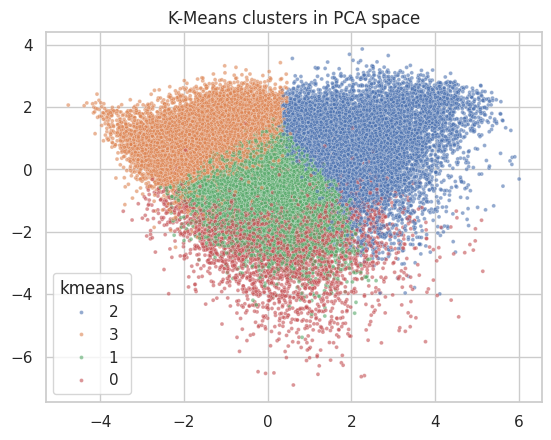

In [ ]:
from sklearn.decomposition import PCA
full = PCA(random_state=RS).fit(X)
cum = np.cumsum(full.explained_variance_ratio_)
n90 = int(np.argmax(cum >= 0.90)) + 1
print("Components for 90% variance:", n90, "| PC1+PC2 explain:", round(cum[1]*100, 1), "%")

plt.plot(range(1, len(cum)+1), cum, "o-"); plt.axhline(0.9, ls="--")
plt.title("PCA cumulative explained variance"); save("pca_variance"); plt.show()

pca = PCA(n_components=n90, random_state=RS).fit(X)
Xp = pca.transform(X)
sns.scatterplot(x=Xp[:,0], y=Xp[:,1], hue=df["kmeans"].astype(str), s=8, alpha=.6)
plt.title("K-Means clusters in PCA space"); save("pca_kmeans"); plt.show()

km_pca = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Xp)

ward [np.float64(0.132), np.float64(0.122), np.float64(0.139), np.float64(0.153), np.float64(0.077), np.float64(0.047), np.float64(0.051)] (k=2..8)
complete [np.float64(0.247), np.float64(0.157), np.float64(0.161), np.float64(0.166), np.float64(0.16), np.float64(0.157), np.float64(0.077)] (k=2..8)
average [np.float64(0.473), np.float64(0.365), np.float64(0.29), np.float64(0.286), np.float64(0.25), np.float64(0.197), np.float64(0.188)] (k=2..8)


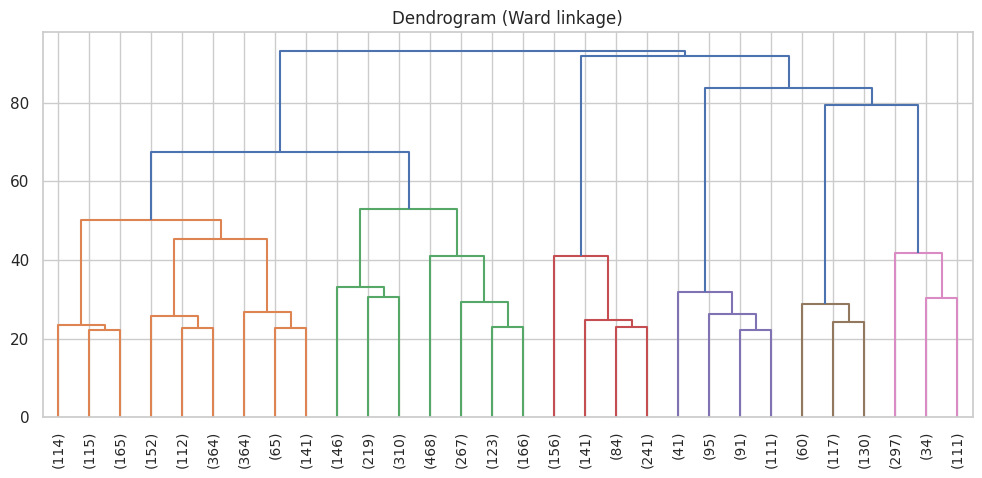

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import AgglomerativeClustering

idx = np.sort(np.random.RandomState(RS).choice(len(X), 5000, replace=False))   # fixed random sample
Xs = X[idx]

for method in ["ward", "complete", "average"]:
    Z = linkage(Xs, method=method)
    print(method, [round(silhouette_score(Xs, fcluster(Z, kk, "maxclust")), 3) for kk in range(2, 9)], "(k=2..8)")

Zw = linkage(Xs, method="ward")
plt.figure(figsize=(12,5)); dendrogram(Zw, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogram (Ward linkage)"); save("dendrogram"); plt.show()

In [ ]:
k_h = 4     # <-- choose from the dendrogram and scores
agg = AgglomerativeClustering(n_clusters=k_h, linkage="ward").fit(Xs)
print(pd.Series(agg.labels_).value_counts().sort_index())

0     749
1    3291
2     622
3     338
Name: count, dtype: int64


In [ ]:
def score(name, labels):
    sizes = pd.Series(labels).value_counts(normalize=True)*100
    return {"method": name, "silhouette": silhouette_score(Xs, labels),
            "davies_bouldin": davies_bouldin_score(Xs, labels),
            "calinski_harabasz": calinski_harabasz_score(Xs, labels),
            "smallest_cluster_%": sizes.min(), "largest_cluster_%": sizes.max()}

table = pd.DataFrame([score("K-Means", km.predict(Xs)),
                      score("Agglomerative (Ward)", agg.labels_),
                      score("K-Means on PCA", km_pca.predict(Xp[idx]))]).round(3)
table.to_csv(f"{BASE}/model_comparison.csv", index=False)
table

,method,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_%,largest_cluster_%
0,K-Means,0.099,2.361,505.934,7.42,41.88
1,Agglomerative (Ward),0.139,2.295,401.135,6.76,65.82
2,K-Means on PCA,0.093,2.393,496.850,9.74,40.70


,age_mid,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
kmeans,,,,,,,,,
0,63.83,4.04,43.76,1.09,15.54,0.73,1.45,0.49,7.74
1,72.34,3.73,43.53,0.67,13.62,0.35,0.00,0.20,8.22
2,66.50,7.79,55.21,3.02,25.54,0.20,0.01,0.19,8.12
3,56.35,2.72,33.79,1.41,11.83,0.15,0.00,0.06,5.26


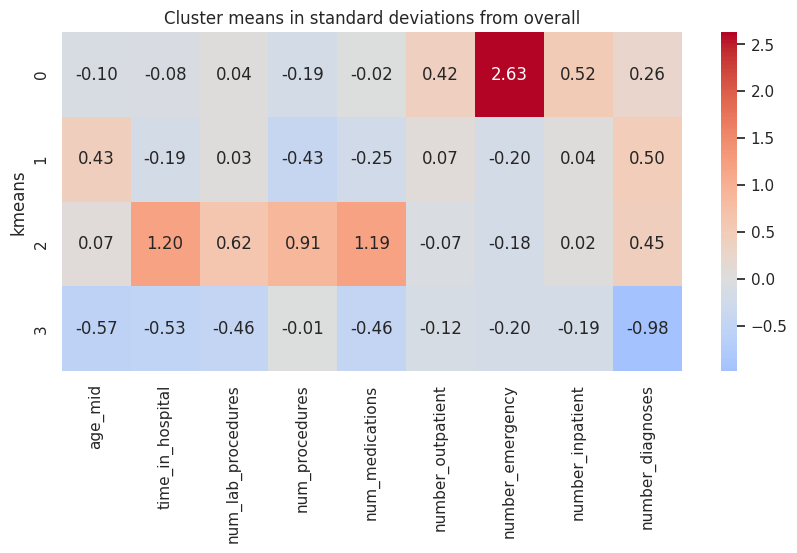

Utilisation index per cluster (0 = average):
kmeans
0    0.48
1   -0.13
2    0.53
3   -0.28
dtype: float64


In [ ]:
prof = df.groupby("kmeans")[num_cols].mean().round(2)
display(prof)
z = (prof - df[num_cols].mean()) / df[num_cols].std()
plt.figure(figsize=(10, 2+0.6*len(z))); sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cluster means in standard deviations from overall"); save("cluster_heatmap"); plt.show()

use = ["time_in_hospital","num_lab_procedures","num_procedures","num_medications",
       "number_outpatient","number_emergency","number_inpatient"]
zz = (df[use] - df[use].mean()) / df[use].std()
print("Utilisation index per cluster (0 = average):")
print(zz.groupby(df["kmeans"]).mean().mean(axis=1).round(2))

In [ ]:
for col in ["admission_type_group","discharge_group","specialty_group","age","readmitted","race"]:
    print(col, "(% of each cluster)")
    display((pd.crosstab(df["kmeans"], df[col].fillna("Unknown"), normalize="index")*100).round(1))

admission_type_group (% of each cluster)


admission_type_group,Elective,Emergency,Other/Unknown,Urgent
kmeans,,,,
0,13.9,56.9,12.0,17.1
1,10.2,64.0,10.3,15.5
2,26.2,43.3,11.3,19.2
3,28.7,37.3,12.4,21.5


discharge_group (% of each cluster)


discharge_group,Facility/Transfer,Home,Home with services,Other/Unknown
kmeans,,,,
0,20.5,63.3,14.3,1.9
1,25.3,57.4,12.8,4.5
2,27.0,47.4,19.5,6.2
3,6.8,81.4,5.5,6.3


specialty_group (% of each cluster)


specialty_group,Cardiology,Emergency/Trauma,Family/GeneralPractice,InternalMedicine,Orthopedics,Orthopedics-Reconstructive,Other,Radiologist,Surgery-General,Unknown
kmeans,,,,,,,,,,
0,4.0,8.7,8.3,15.5,0.6,0.7,7.3,0.9,2.9,51.1
1,3.9,7.2,6.9,16.2,0.8,0.9,5.1,0.6,2.0,56.4
2,7.2,5.0,5.8,13.7,1.9,1.5,11.0,1.5,3.3,49.1
3,8.4,5.4,8.0,14.9,2.7,2.4,15.7,1.7,4.6,36.1


... (2 outputs left out)

readmitted (% of each cluster)


readmitted,<30,>30,NO
kmeans,,,
0,12.1,44.5,43.4
1,9.6,34.7,55.7
2,10.8,32.5,56.7
3,6.3,24.7,69.0


race (% of each cluster)


race,AfricanAmerican,Asian,Caucasian,Hispanic,Other,Unknown
kmeans,,,,,,
0,22.5,0.4,72.1,2.4,1.6,1.0
1,15.1,0.7,78.7,1.7,1.4,2.3
2,16.2,0.5,77.2,1.6,1.8,2.7
3,22.0,0.9,68.6,3.0,1.9,3.7


In [ ]:
import joblib
bundle = {"pre": pre, "km": km, "caps": caps, "num_cols": num_cols, "cat_cols": cat_cols,
          "age_groups": sorted(df["age"].unique()),
          "cat_options": {c: sorted(df[c].unique()) for c in cat_cols},
          "ranges": {c: (int(df[c].min()), int(df[c].max()), int(df[c].median())) for c in num_cols if c != "age_mid"}}
joblib.dump(bundle, f"{BASE}/bundle.joblib")
print("Saved. Keep this scikit-learn version in mind:", sklearn.__version__)

Saved. Keep this scikit-learn version in mind: 1.6.1


In [ ]:
def assign(p):
    row = dict(p); row["age_mid"] = int(row.pop("age").strip("[)").split("-")[0]) + 5
    r = pd.DataFrame([row])
    for c in num_cols: r[c] = r[c].clip(upper=caps[c])
    x = pre.transform(r[num_cols + cat_cols])
    return int(km.predict(x)[0]), km.transform(x).round(2)

print(assign({"age":"[70-80)","time_in_hospital":9,"num_lab_procedures":60,"num_procedures":3,
              "num_medications":24,"number_outpatient":1,"number_emergency":1,"number_inpatient":2,
              "number_diagnoses":9,"admission_type_group":"Emergency","admission_source_group":"Emergency Room",
              "discharge_group":"Home","specialty_group":"Other","change":"Ch","diabetesMed":"Yes"}))

(0, array([[4.42, 5.7 , 5.09, 6.48]]))


In [ ]:
%%writefile /content/app.py
import joblib, pandas as pd, streamlit as st
b = joblib.load("bundle.joblib")
pre, km, caps, num_cols, cat_cols = b["pre"], b["km"], b["caps"], b["num_cols"], b["cat_cols"]
st.title("Hospital Patient Grouping")
st.warning("Analytical similarity grouping only. This is not a medical assessment.")
p = {"age": st.selectbox("Age group", b["age_groups"])}
for c in num_cols:
    if c != "age_mid":
        lo, hi, med = b["ranges"][c]
        p[c] = st.number_input(c, min_value=lo, max_value=hi, value=med)
for c in cat_cols:
    p[c] = st.selectbox(c, b["cat_options"][c])
if st.button("Find nearest cluster"):
    row = dict(p); row["age_mid"] = int(row.pop("age").strip("[)").split("-")[0]) + 5
    r = pd.DataFrame([row])
    for c in num_cols: r[c] = r[c].clip(upper=caps[c])
    x = pre.transform(r[num_cols + cat_cols])
    st.subheader(f"Nearest cluster: {int(km.predict(x)[0])}")
    st.write("Distances to cluster centres:", km.transform(x).round(2))

Writing /content/app.py


In [ ]:
import sklearn, numpy, pandas, joblib
print(f"pip install streamlit scikit-learn=={sklearn.__version__} numpy=={numpy.__version__} pandas=={pandas.__version__} joblib=={joblib.__version__}")

pip install streamlit scikit-learn==1.6.1 numpy==2.4.6 pandas==2.2.3 joblib==1.6.0


In [ ]:
from google.colab import files
files.download("/content/app.py")
files.download("/content/bundle.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>